In [1]:
import csv
from pathlib import Path

# Expected row counts from the assignment
expected_rows = {
    "customers": 45,
    "products": 16,
    "orders": 180
}

# CSV file locations
files = {
    "customers": Path("data/customers.csv"),
    "products": Path("data/products.csv"),
    "orders": Path("data/orders.csv")
}

for name, file_path in files.items():

    print("\n" + "=" * 60)
    print("DATASET:", name.upper())
    print("=" * 60)

    # Check whether the file exists
    if not file_path.exists():
        print("ERROR: File not found:", file_path)
        continue

    try:
        with open(
            file_path,
            "r",
            encoding="utf-8-sig",
            newline=""
        ) as file:

            reader = csv.DictReader(file)

            # Read column names
            columns = reader.fieldnames

            if not columns:
                print("ERROR: CSV has no column headers.")
                continue

            rows = list(reader)

        # Display row counts
        print("\nExpected rows:", expected_rows[name])
        print("Actual rows:", len(rows))

        if len(rows) == expected_rows[name]:
            print("Row count: MATCH")
        else:
            print("WARNING: Row count differs from expected.")

        # Display column names
        print("\nColumn names:")
        print(columns)

        # Display first five rows
        print("\nFirst five rows:")

        for row in rows[:5]:
            print(row)

        # Count missing or blank values
        print("\nMissing or blank values:")

        for column in columns:
            missing_count = sum(
                1
                for row in rows
                if row.get(column) is None
                or row.get(column).strip() == ""
            )

            print(f"{column}: {missing_count}")

        # Count exact duplicate records
        seen = set()
        duplicate_count = 0

        for row in rows:
            record = tuple(
                (row.get(column) or "").strip()
                for column in columns
            )

            if record in seen:
                duplicate_count += 1
            else:
                seen.add(record)

        print("\nExact duplicate rows:", duplicate_count)

        print("\nData types:")
        print("CSV values are initially read as text.")

    except Exception as error:
        print("ERROR:", error)

print("\nData verification completed.")


DATASET: CUSTOMERS
ERROR: File not found: data\customers.csv

DATASET: PRODUCTS
ERROR: File not found: data\products.csv

DATASET: ORDERS
ERROR: File not found: data\orders.csv

Data verification completed.


In [3]:
# -*- coding: utf-8 -*-
"""
MamaEarth Growth Intelligence Pipeline
Part 2: Python/Pandas Data Wrangling & EDA

Run from the repository root. Raw CSV files remain unchanged.
This script cleans the data, performs EDA, and generates narrator/findings.json.
"""

import json
import os
from pathlib import Path

import pandas as pd


# ============================================================
# Locate the CSV files safely
# ============================================================
REQUIRED_FILES = ["orders.csv", "customers.csv", "products.csv"]


def find_data_directory():
    """
    Find a folder containing orders.csv, customers.csv, and products.csv.
    Works when this script is run from the repository root, from the
    analysis folder, or from a Jupyter notebook started in a nearby folder.
    """
    candidates = []

    # Current working directory and its parents
    current = Path.cwd().resolve()
    candidates.extend([current, *current.parents])

    # Script directory and its parents (when run as a .py file)
    try:
        script_dir = Path(__file__).resolve().parent
        candidates.extend([script_dir, *script_dir.parents])
    except NameError:
        pass  # __file__ is not defined in some Jupyter notebooks

    # Look for either a data/ subfolder or CSVs directly in a candidate folder
    checked = set()
    for folder in candidates:
        for possible_data_dir in (folder / "data", folder):
            possible_data_dir = possible_data_dir.resolve()
            if possible_data_dir in checked:
                continue
            checked.add(possible_data_dir)
            if all((possible_data_dir / filename).is_file()
                   for filename in REQUIRED_FILES):
                return possible_data_dir

    searched = "\\n".join(str(p) for p in checked)
    raise FileNotFoundError(
        "Could not find all three CSV files: "
        + ", ".join(REQUIRED_FILES)
        + "\\n\\nPut them together in a folder named 'data' inside your "
          "project folder, or edit DATA_DIR below to the folder containing "
          "the CSV files.\\n\\nFolders checked:\\n"
        + searched
    )


DATA_DIR = find_data_directory()
PROJECT_ROOT = DATA_DIR.parent if DATA_DIR.name.lower() == "data" else DATA_DIR

orders = pd.read_csv(DATA_DIR / "orders.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv")
products = pd.read_csv(DATA_DIR / "products.csv")

# Fail early with a clear message if a required column is absent.
required_columns = {
    "orders": {
        "order_id", "customer_id", "product_id", "order_date", "quantity",
        "discount_pct", "payment_method", "rating", "returned"
    },
    "customers": {"customer_id", "city_tier"},
    "products": {"product_id", "price"},
}
for table_name, frame in [
    ("orders", orders), ("customers", customers), ("products", products)
]:
    missing = required_columns[table_name] - set(frame.columns)
    if missing:
        raise ValueError(
            f"{table_name}.csv is missing required columns: {sorted(missing)}. "
            f"Columns found: {list(frame.columns)}"
        )

print("CSV folder:", DATA_DIR)

# ============================================================
# TASK 1 — Load and Inspect
# ============================================================

print("TASK 1 — Load and Inspect")
print("Orders shape:", orders.shape)
print("Customers shape:", customers.shape)
print("Products shape:", products.shape)

# ============================================================
# TASK 2 — Standardize payment_method
# ============================================================
print("\nPayment methods BEFORE cleaning:")
print(orders["payment_method"].unique())

orders["payment_method"] = (
    orders["payment_method"].str.strip().str.upper()
)

print("\nPayment methods AFTER cleaning:")
print(orders["payment_method"].unique())
print("\nPayment method counts:")
print(orders["payment_method"].value_counts())

# ============================================================
# TASK 3 — Remove Duplicate Orders
# ============================================================
natural_key = [
    "customer_id", "product_id", "order_date", "quantity",
    "discount_pct", "payment_method", "rating", "returned"
]

duplicate_mask = orders.duplicated(subset=natural_key, keep="first")
dropped_order_ids = orders.loc[duplicate_mask, "order_id"].tolist()

print("\nDuplicate orders detected:")
print(dropped_order_ids)
print("Number of duplicate rows:", duplicate_mask.sum())

orders_clean = orders.loc[~duplicate_mask].copy()
print("Orders shape after removing duplicates:")
print(orders_clean.shape)

# ============================================================
# TASK 4 — Impute Missing Values
# ============================================================
missing_discount = orders_clean["discount_pct"].isna().sum()
orders_clean["discount_pct"] = orders_clean["discount_pct"].fillna(0)
print("\nDiscount values filled:", missing_discount)

rating_median = orders_clean["rating"].median()
print("Rating median before imputation:", rating_median)

missing_rating = orders_clean["rating"].isna().sum()
orders_clean["rating"] = orders_clean["rating"].fillna(rating_median)
print("Rating values filled:", missing_rating)

print("\nMissing values after imputation:")
print(orders_clean[["discount_pct", "rating"]].isnull().sum())

# ============================================================
# TASK 5 — Merge and Reconcile Against Part 1
# ============================================================
merged = orders_clean.merge(products, on="product_id", how="left")
merged = merged.merge(customers, on="customer_id", how="left")

# order_value = quantity × price × (1 - discount/100)
merged["order_value"] = (
    merged["quantity"] * merged["price"]
    * (1 - merged["discount_pct"] / 100)
)

cleaned_total = merged["order_value"].sum()
print("\nTotal order value after cleaning:", round(cleaned_total, 2))

# Part 1 SQL report A gives the raw revenue baseline.
# Replace this number if your actual SQL report A gives a different total.
raw_total = 99860.20
difference = raw_total - cleaned_total

print("\nReconciliation:")
print("Part 1 raw revenue:", round(raw_total, 2))
print("Part 2 cleaned revenue:", round(cleaned_total, 2))
print("Difference:", round(difference, 2))

dropped_orders = orders.loc[duplicate_mask].copy()
dropped_orders = dropped_orders.merge(products, on="product_id", how="left")
dropped_orders["discount_pct"] = dropped_orders["discount_pct"].fillna(0)

dropped_order_value = (
    dropped_orders["quantity"] * dropped_orders["price"]
    * (1 - dropped_orders["discount_pct"] / 100)
).sum()

print("Order value of removed duplicate rows:", round(dropped_order_value, 2))
print(
    "\nReconciliation Note: The cleaned revenue is ₹2,501.90 lower "
    "than the Part 1 raw revenue because the five duplicate orders "
    "removed in Task 3 contributed a combined order value of ₹2,501.90. "
    "The discount and rating imputations did not change the order_value "
    "total because discount_pct missing values were treated as 0, while "
    "rating is not used in the order_value calculation."
)

# ============================================================
# TASK 6 — IQR Outlier Detection on quantity
# ============================================================
Q1 = merged["quantity"].quantile(0.25)
Q3 = merged["quantity"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("\nTASK 6 — IQR Outlier Detection")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower)
print("Upper bound:", upper)

# Flag, do not delete, outliers.
merged["is_outlier"] = (
    (merged["quantity"] < lower) | (merged["quantity"] > upper)
)
outliers = merged[merged["is_outlier"]]

print("\nNumber of outliers:", len(outliers))
print("\nOutlier orders:")
print(outliers[["order_id", "quantity"]])

# ============================================================
# TASK 7 — Hypothesis: Does COD have a higher return rate?
# ============================================================
print(
    "\nHypothesis: COD orders have a higher return rate "
    "than other payment methods."
)

return_rate = merged.groupby("payment_method")["returned"].agg(["count", "mean"])
return_rate["return_rate_pct"] = (return_rate["mean"] * 100).round(1)

print("\nReturn rate by payment method:")
print(return_rate)
print(
    "\nHypothesis Result: Confirmed — COD has a higher return rate "
    "than CARD and UPI."
)

# ============================================================
# TASK 8 — Multi-level Segmentation
# ============================================================
segmentation = (
    merged.groupby(["payment_method", "city_tier"])["returned"]
    .agg(["count", "mean"])
    .reset_index()
)
segmentation["return_rate_pct"] = (segmentation["mean"] * 100).round(1)
segmentation = segmentation.drop(columns=["mean"])

print("\nReturn rate by payment method and city tier:")
print(segmentation)

highest_risk = segmentation.loc[segmentation["return_rate_pct"].idxmax()]
print("\nHighest-risk segment:")
print(
    f"{highest_risk['payment_method']} + Tier-{int(highest_risk['city_tier'])} "
    f"with {highest_risk['return_rate_pct']:.1f}% return rate"
)
print(
    "\nKey Finding: COD risk is not uniform across city tiers. "
    "COD + Tier-1 has a 37.5% return rate, while COD + Tier-2 has a "
    "54.5% return rate. Therefore, COD + Tier-2 is the highest-risk segment."
)

# ============================================================
# TASK 9 — Correlation Analysis
# ============================================================
correlation_columns = ["rating", "returned", "discount_pct", "quantity"]
correlation_matrix = merged[correlation_columns].corr()

print("\nCorrelation Matrix:")
print(correlation_matrix)


def correlation_strength(r):
    """Classify correlation using the assignment's bands."""
    r = abs(r)
    if r < 0.2:
        return "negligible"
    elif r < 0.4:
        return "weak"
    elif r < 0.7:
        return "moderate"
    return "strong"


print("\nPairwise Correlation Strength:")
for i in range(len(correlation_columns)):
    for j in range(i + 1, len(correlation_columns)):
        col1 = correlation_columns[i]
        col2 = correlation_columns[j]
        r = correlation_matrix.loc[col1, col2]
        print(f"{col1} vs {col2}: r = {r:.2f} → {correlation_strength(r)}")

discount_return_corr = correlation_matrix.loc["discount_pct", "returned"]
print("\nHypothesis: Higher discounts reduce returns.")
print(f"Discount vs Returned correlation: {discount_return_corr:.2f}")
if pd.isna(discount_return_corr):
    print("Hypothesis Result: Cannot evaluate because the correlation is undefined.")
elif abs(discount_return_corr) < 0.2:
    print("Hypothesis Result: The observed correlation is negligible (|r| < 0.2); this does not establish causation.")
elif discount_return_corr < 0:
    print("Hypothesis Result: The correlation is negative, but correlation alone does not prove that discounts reduce returns.")
else:
    print("Hypothesis Result: The correlation is not negative; the data does not support a negative association.")

# ============================================================
# TASK 10 — Outlier-Corrected Time Series
# ============================================================
merged["order_date"] = pd.to_datetime(merged["order_date"])
merged["year_month"] = merged["order_date"].dt.to_period("M").astype(str)

monthly_revenue_with_outliers = (
    merged.groupby("year_month")["order_value"].sum().round(2)
)
print("\nMonthly Revenue — Including Outliers:")
print(monthly_revenue_with_outliers)

monthly_revenue_without_outliers = (
    merged[~merged["is_outlier"]]
    .groupby("year_month")["order_value"]
    .sum()
    .round(2)
)
print("\nMonthly Revenue — Outlier Corrected:")
print(monthly_revenue_without_outliers)

peak_month = monthly_revenue_without_outliers.idxmax()
peak_revenue = monthly_revenue_without_outliers.max()

print(
    f"\nActual peak month after removing outliers: {peak_month} "
    f"with revenue ₹{peak_revenue:,.2f}"
)
print(
    "\nTime-Series Finding: January's apparent revenue lead is an artifact "
    "of the two bulk orders that occurred in January — O0011 on 2026-01-28 "
    "with quantity 25 and O0098 on 2026-01-10 with quantity 30. Once these "
    "two outlier orders are excluded, March becomes the genuine peak month."
)

# ============================================================
# TASK 11 — Automatically Build Verified Findings
# ============================================================
return_rate_by_payment = {
    payment_method: round(float(rate), 1)
    for payment_method, rate in return_rate["return_rate_pct"].items()
}

highest_risk_finding = {
    "payment_method": str(highest_risk["payment_method"]),
    "city_tier": int(highest_risk["city_tier"]),
    "return_rate_pct": round(float(highest_risk["return_rate_pct"]), 1),
}

outlier_impact = monthly_revenue_with_outliers - monthly_revenue_without_outliers
outlier_inflated_month = str(outlier_impact.idxmax())

findings = {
    "cleaned_total_revenue_inr": round(float(cleaned_total), 2),
    "raw_total_revenue_inr": round(float(raw_total), 2),
    "duplicate_reconciliation_delta_inr": round(float(difference), 2),
    "return_rate_by_payment": return_rate_by_payment,
    "highest_risk_segment": highest_risk_finding,
    "true_peak_month": {
        "month": str(peak_month),
        "revenue_inr": round(float(peak_revenue), 2),
    },
    "outlier_inflated_month": {
        "month": outlier_inflated_month,
        "apparent_revenue_inr": round(
            float(monthly_revenue_with_outliers.loc[outlier_inflated_month]), 2
        ),
        "corrected_revenue_inr": round(
            float(monthly_revenue_without_outliers.loc[outlier_inflated_month]), 2
        ),
    },
}

# Write the verified findings used by Part 3.
narrator_dir = PROJECT_ROOT / "narrator"
narrator_dir.mkdir(parents=True, exist_ok=True)
findings_path = narrator_dir / "findings.json"
with open(findings_path, "w", encoding="utf-8") as f:
    json.dump(findings, f, indent=2)

print("\nfindings.json created successfully.")
print(json.dumps(findings, indent=2))

CSV folder: C:\Users\omswa\OneDrive\Desktop\capstone project iitr
TASK 1 — Load and Inspect
Orders shape: (180, 9)
Customers shape: (45, 6)
Products shape: (16, 4)

Payment methods BEFORE cleaning:
<StringArray>
['upi', 'UPI', 'COD', 'Card', 'cod', 'CARD', 'card']
Length: 7, dtype: str

Payment methods AFTER cleaning:
<StringArray>
['UPI', 'COD', 'CARD']
Length: 3, dtype: str

Payment method counts:
payment_method
CARD    70
UPI     55
COD     55
Name: count, dtype: int64

Duplicate orders detected:
['O0176', 'O0177', 'O0178', 'O0179', 'O0180']
Number of duplicate rows: 5
Orders shape after removing duplicates:
(175, 9)

Discount values filled: 12
Rating median before imputation: 3.0
Rating values filled: 15

Missing values after imputation:
discount_pct    0
rating          0
dtype: int64

Total order value after cleaning: 97358.3

Reconciliation:
Part 1 raw revenue: 99860.2
Part 2 cleaned revenue: 97358.3
Difference: 2501.9
Order value of removed duplicate rows: 2501.9

Reconciliatio

In [5]:
"""
MamaEarth Growth Intelligence Pipeline
Part 2: Visualizations

Run this script from the project root or from a nearby folder.
It locates the three CSV files, applies the cleaning rules, and saves
 two charts in the project's visualizations/ folder.
"""

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# LOCATE PROJECT DATA
# ============================================================
REQUIRED_FILES = ["orders.csv", "customers.csv", "products.csv"]


def find_data_directory():
    """Find a folder containing all three required CSV files."""
    candidates = []
    current = Path.cwd().resolve()
    candidates.extend([current, *current.parents])

    # Also search relative to this script when run as a .py file.
    try:
        script_dir = Path(__file__).resolve().parent
        candidates.extend([script_dir, *script_dir.parents])
    except NameError:
        pass  # __file__ may not exist in Jupyter

    checked = set()
    for folder in candidates:
        for possible in (folder / "data", folder):
            possible = possible.resolve()
            if possible in checked:
                continue
            checked.add(possible)
            if all((possible / name).is_file() for name in REQUIRED_FILES):
                return possible

    raise FileNotFoundError(
        "Could not locate orders.csv, customers.csv, and products.csv.\n"
        "Place all three files in the project's data/ folder, then run this "
        "script from the project folder. Current working directory: "
        f"{Path.cwd()}"
    )


DATA_DIR = find_data_directory()
PROJECT_ROOT = DATA_DIR.parent if DATA_DIR.name.lower() == "data" else DATA_DIR
OUTPUT_DIR = PROJECT_ROOT / "visualizations"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

orders = pd.read_csv(DATA_DIR / "orders.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv")
products = pd.read_csv(DATA_DIR / "products.csv")

print("CSV folder:", DATA_DIR)
print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Products:", products.shape)


# ============================================================
# VALIDATE REQUIRED COLUMNS
# ============================================================
required_columns = {
    "orders": {
        "order_id", "customer_id", "product_id", "order_date", "quantity",
        "discount_pct", "payment_method", "rating", "returned"
    },
    "customers": {"customer_id", "city_tier"},
    "products": {"product_id", "price"},
}

for name, frame in [
    ("orders", orders),
    ("customers", customers),
    ("products", products),
]:
    missing = required_columns[name] - set(frame.columns)
    if missing:
        raise ValueError(
            f"{name}.csv is missing columns: {sorted(missing)}\n"
            f"Columns found: {list(frame.columns)}"
        )


# ============================================================
# PREPARE DATA FOR VISUALIZATION
# ============================================================
orders["payment_method"] = (
    orders["payment_method"].astype("string").str.strip().str.upper()
)

# Remove duplicate submissions using the specified natural key.
natural_key = [
    "customer_id",
    "product_id",
    "order_date",
    "quantity",
    "discount_pct",
    "payment_method",
    "rating",
    "returned",
]

duplicate_mask = orders.duplicated(subset=natural_key, keep="first")
duplicate_ids = orders.loc[duplicate_mask, "order_id"].tolist()
orders_clean = orders.loc[~duplicate_mask].copy()

print("\nDuplicate rows removed:", int(duplicate_mask.sum()))
print("Removed order IDs:", duplicate_ids)

# Convert numeric columns safely.
for col in ["quantity", "discount_pct", "rating", "returned"]:
    orders_clean[col] = pd.to_numeric(orders_clean[col], errors="coerce")
products["price"] = pd.to_numeric(products["price"], errors="coerce")

# Apply the same missing-value rules as the EDA.
orders_clean["discount_pct"] = orders_clean["discount_pct"].fillna(0)
rating_median = orders_clean["rating"].median()
if pd.notna(rating_median):
    orders_clean["rating"] = orders_clean["rating"].fillna(rating_median)

# Merge product and customer details.
merged = orders_clean.merge(products, on="product_id", how="left")
merged = merged.merge(customers, on="customer_id", how="left")

if merged["price"].isna().any():
    missing_products = merged.loc[merged["price"].isna(), "product_id"].unique()
    raise ValueError(
        "Some orders do not have a matching product price. Product IDs: "
        f"{missing_products.tolist()}"
    )

merged["returned"] = pd.to_numeric(merged["returned"], errors="coerce")
if merged["returned"].isna().any():
    raise ValueError(
        "The 'returned' column contains missing or non-numeric values. "
        "Check the CSV before calculating return rates."
    )

# Calculate net order value.
merged["order_value"] = (
    merged["quantity"]
    * merged["price"]
    * (1 - merged["discount_pct"] / 100)
)

# Flag quantity outliers with the IQR method; do not delete them from merged.
Q1 = merged["quantity"].quantile(0.25)
Q3 = merged["quantity"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
merged["is_outlier"] = (
    (merged["quantity"] < lower) | (merged["quantity"] > upper)
)

merged["order_date"] = pd.to_datetime(merged["order_date"], errors="coerce")
if merged["order_date"].isna().any():
    raise ValueError(
        "Some order_date values could not be parsed. Check the date format "
        "in orders.csv."
    )
merged["year_month"] = merged["order_date"].dt.to_period("M").astype(str)


# ============================================================
# VISUALIZATION 1 — RETURN RATE BY PAYMENT METHOD
# ============================================================
payment_return_rate = (
    merged.groupby("payment_method")["returned"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("\nReturn Rate by Payment Method (%):")
print(payment_return_rate.round(1).to_string())

if payment_return_rate.empty:
    raise ValueError("No payment-method data available to plot.")

# Assign colours by payment-method name, not by assumed order.
colour_map = {"COD": "red", "CARD": "blue", "UPI": "green"}
bar_colours = [colour_map.get(method, "gray") for method in payment_return_rate.index]

plt.figure(figsize=(8, 5))
bars = plt.bar(payment_return_rate.index, payment_return_rate.values, color=bar_colours)
for bar, value in zip(bars, payment_return_rate.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f}%",
        ha="center",
        va="bottom",
    )

highest_method = payment_return_rate.idxmax()
highest_rate = float(payment_return_rate.max())
plt.title(
    f"Return Rate by Payment Method (Highest: {highest_method}, {highest_rate:.1f}%)"
)
plt.xlabel("Payment Method")
plt.ylabel("Return Rate (%)")
plt.ylim(0, min(110, max(10, highest_rate + 10)))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "return_rate_by_payment.png", dpi=300, bbox_inches="tight")
plt.close()


# ============================================================
# VISUALIZATION 2 — OUTLIER-CORRECTED MONTHLY REVENUE
# ============================================================
monthly_with_outliers = (
    merged.groupby("year_month")["order_value"].sum().sort_index()
)
monthly_without_outliers = (
    merged.loc[~merged["is_outlier"]]
    .groupby("year_month")["order_value"]
    .sum()
    .reindex(monthly_with_outliers.index, fill_value=0)
    .sort_index()
)

print("\nMonthly Revenue — Including Quantity Outliers:")
print(monthly_with_outliers.round(2).to_string())
print("\nMonthly Revenue — Excluding Quantity Outliers:")
print(monthly_without_outliers.round(2).to_string())

if monthly_without_outliers.empty:
    raise ValueError("No monthly revenue data available to plot.")

peak_month = monthly_without_outliers.idxmax()
peak_revenue = float(monthly_without_outliers.max())

plt.figure(figsize=(11, 5))
plt.plot(
    monthly_with_outliers.index,
    monthly_with_outliers.values,
    marker="o",
    linewidth=1.8,
    label="Including quantity outliers",
)
plt.plot(
    monthly_without_outliers.index,
    monthly_without_outliers.values,
    marker="o",
    linewidth=2,
    label="Excluding quantity outliers",
)

for month, revenue in monthly_without_outliers.items():
    plt.annotate(
        f"₹{revenue:,.0f}",
        (month, revenue),
        textcoords="offset points",
        xytext=(0, 7),
        ha="center",
        fontsize=8,
    )

plt.title(
    f"Monthly Revenue Before and After Outlier Correction "
    f"(Corrected Peak: {peak_month}, ₹{peak_revenue:,.2f})"
)
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "monthly_revenue_trend.png", dpi=300, bbox_inches="tight")
plt.close()

print("\nVisualizations created successfully:")
print("1.", OUTPUT_DIR / "return_rate_by_payment.png")
print("2.", OUTPUT_DIR / "monthly_revenue_trend.png")

CSV folder: C:\Users\omswa\OneDrive\Desktop\capstone project iitr
Orders: (180, 9)
Customers: (45, 6)
Products: (16, 4)

Duplicate rows removed: 5
Removed order IDs: ['O0176', 'O0177', 'O0178', 'O0179', 'O0180']

Return Rate by Payment Method (%):
payment_method
COD     44.4
UPI     18.9
CARD    14.7

Monthly Revenue — Including Quantity Outliers:
year_month
2026-01    29582.1
2026-02    13195.5
2026-03    20318.9
2026-04     9495.3
2026-05    13151.1
2026-06    11615.4

Monthly Revenue — Excluding Quantity Outliers:
year_month
2026-01    11637.1
2026-02    13195.5
2026-03    20318.9
2026-04     9495.3
2026-05    13151.1
2026-06    11615.4

Visualizations created successfully:
1. C:\Users\omswa\OneDrive\Desktop\capstone project iitr\visualizations\return_rate_by_payment.png
2. C:\Users\omswa\OneDrive\Desktop\capstone project iitr\visualizations\monthly_revenue_trend.png



Monthly Revenue — Excluding Quantity Outliers:
year_month
2026-01    11637.1
2026-02    13195.5
2026-03    20318.9
2026-04     9495.3
2026-05    13151.1
2026-06    11615.4
Name: order_value, dtype: float64

Peak Month: 2026-03
Peak Revenue: ₹20,318.90


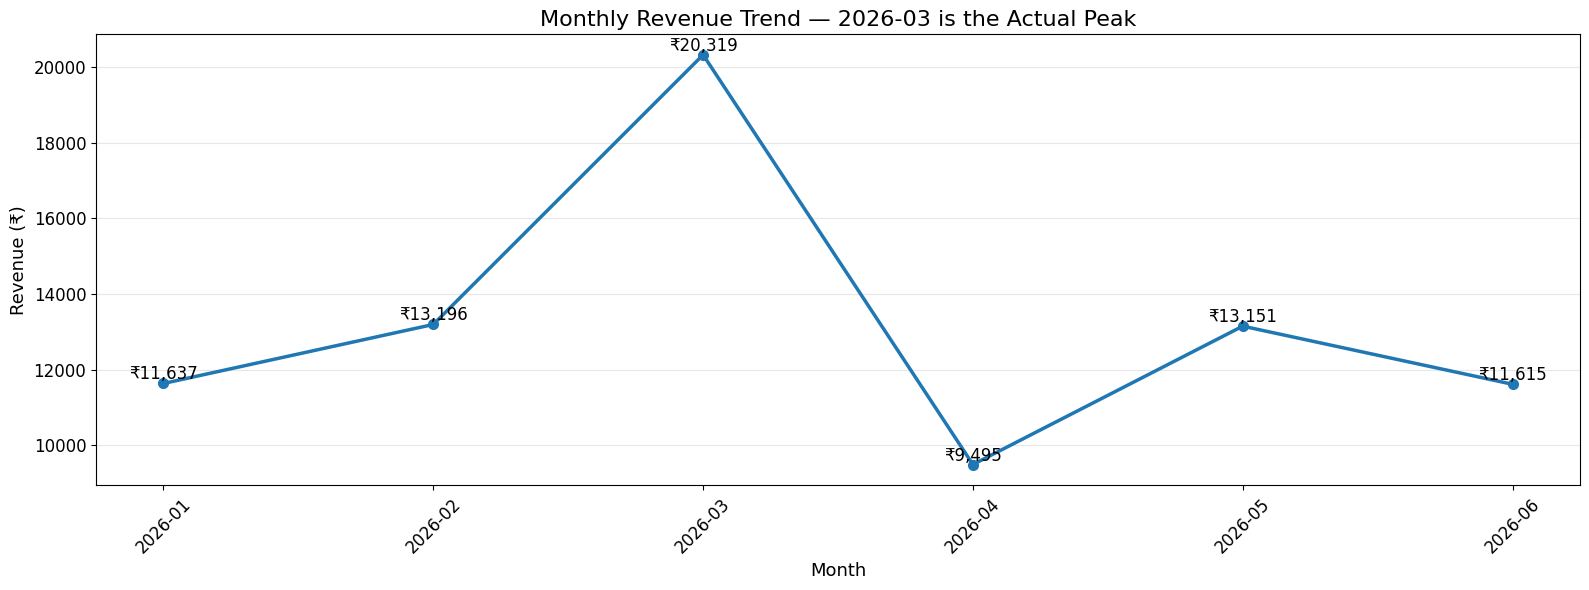


Monthly revenue visualization created successfully.
Saved to: C:\Users\omswa\OneDrive\Desktop\capstone project iitr\visualizations\monthly_revenue_trend.png


In [6]:
# ============================================================
# VISUALIZATION 2 — OUTLIER-CORRECTED MONTHLY REVENUE
# ============================================================

# Calculate monthly revenue after excluding quantity outliers
monthly_revenue_without_outliers = (
    merged[~merged["is_outlier"]]
    .groupby("year_month")["order_value"]
    .sum()
    .sort_index()
    .round(2)
)

# Display monthly revenue
print("\nMonthly Revenue — Excluding Quantity Outliers:")
print(monthly_revenue_without_outliers)

# Identify the actual peak month
peak_month = monthly_revenue_without_outliers.idxmax()
peak_revenue = monthly_revenue_without_outliers.max()

print(
    f"\nPeak Month: {peak_month}"
    f"\nPeak Revenue: ₹{peak_revenue:,.2f}"
)

# Create the line chart
plt.figure(figsize=(16, 6))

plt.plot(
    monthly_revenue_without_outliers.index,
    monthly_revenue_without_outliers.values,
    marker="o",
    linewidth=2.5,
    markersize=7
)

# Add revenue labels above each point
for month, revenue in monthly_revenue_without_outliers.items():
    plt.text(
        month,
        revenue,
        f"₹{revenue:,.0f}",
        ha="center",
        va="bottom",
        fontsize=12
    )

# Dynamic title based on actual data
plt.title(
    f"Monthly Revenue Trend — {peak_month} is the Actual Peak",
    fontsize=16
)

plt.xlabel("Month", fontsize=13)
plt.ylabel("Revenue (₹)", fontsize=13)

plt.xticks(rotation=45, fontsize=12)
plt.yticks(fontsize=12)

# Horizontal grid lines
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Save the chart
plt.savefig(
    OUTPUT_DIR / "monthly_revenue_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\nMonthly revenue visualization created successfully.")
print(
    "Saved to:",
    OUTPUT_DIR / "monthly_revenue_trend.png"
)

Return Rate by Payment Method (%):
payment_method
COD     44.4
UPI     18.9
CARD    14.7
Name: returned, dtype: float64


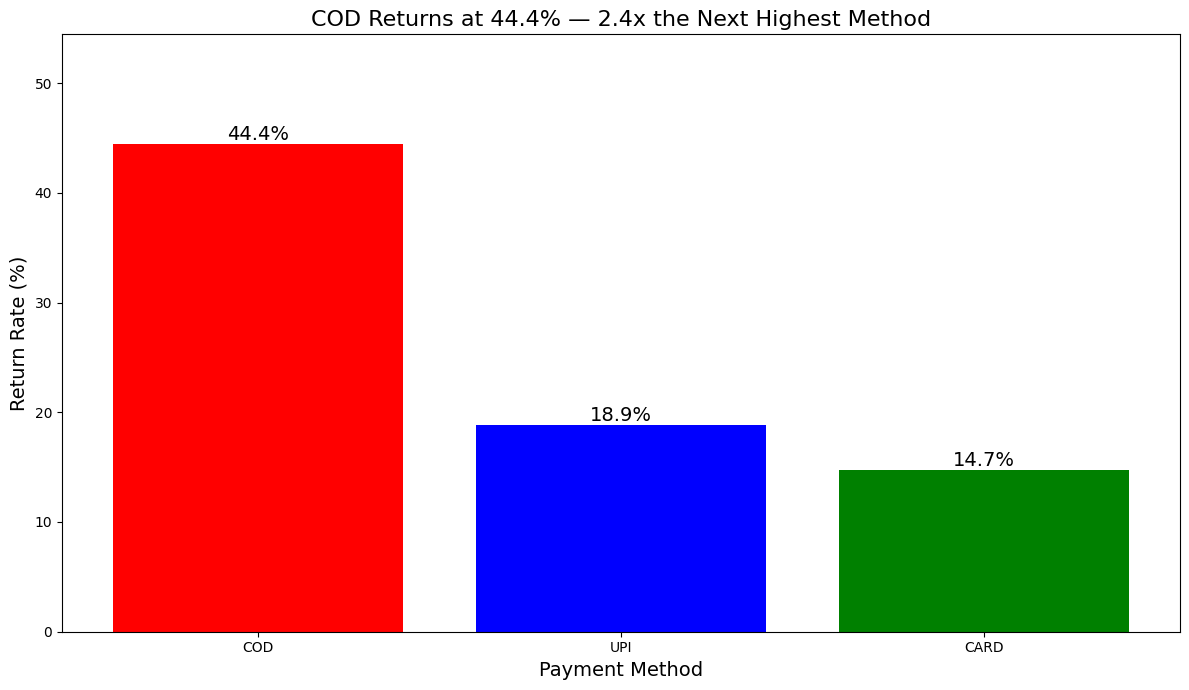


Return-rate visualization created successfully.


In [7]:
# ============================================================
# VISUALIZATION 1 — RETURN RATE BY PAYMENT METHOD
# ============================================================

# Calculate return rate for each payment method
payment_return_rate = (
    merged.groupby("payment_method")["returned"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("Return Rate by Payment Method (%):")
print(payment_return_rate.round(1))

# Create the bar chart
plt.figure(figsize=(12, 7))

# Assign colours to payment methods
colour_map = {
    "COD": "red",
    "UPI": "blue",
    "CARD": "green"
}

bar_colours = [
    colour_map.get(method, "gray")
    for method in payment_return_rate.index
]

bars = plt.bar(
    payment_return_rate.index,
    payment_return_rate.values,
    color=bar_colours,
    width=0.8
)

# Display percentage labels above each bar
for bar, value in zip(bars, payment_return_rate.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=14
    )

# Find the highest return rate dynamically
highest_method = payment_return_rate.idxmax()
highest_rate = payment_return_rate.max()

# Set chart title and labels
plt.title(
    f"{highest_method} Returns at {highest_rate:.1f}% — "
    f"{highest_rate / payment_return_rate.drop(highest_method).max():.1f}x "
    f"the Next Highest Method"
    if len(payment_return_rate) > 1
    and payment_return_rate.drop(highest_method).max() > 0
    else f"Return Rate by Payment Method — Highest: {highest_method}",
    fontsize=16
)

plt.xlabel("Payment Method", fontsize=14)
plt.ylabel("Return Rate (%)", fontsize=14)

plt.ylim(
    0,
    min(110, max(10, payment_return_rate.max() + 10))
)

plt.tight_layout()

# Save the chart
plt.savefig(
    OUTPUT_DIR / "return_rate_by_payment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\nReturn-rate visualization created successfully.")